In [2]:
# Mount Drive
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
# ============================================================
# 1. LOAD BENCHMARK DATASET
# ============================================================

import os
import json
import joblib
import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd

from PIL import Image
from tqdm.auto import tqdm

from transformers import CLIPModel, CLIPProcessor

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

BENCHMARK_DIR = (
    "/content/drive/MyDrive/"
    "EEE6778_Semester_Project/"
    "benchmark_data_folder"
)

BENCHMARK_CSV = os.path.join(
    BENCHMARK_DIR,
    "pdf_benchmark_dataset.csv"
)

benchmark_df = pd.read_csv(BENCHMARK_CSV)

print("Number of benchmark records:", len(benchmark_df))

display(
    benchmark_df[
        [
            "document_id",
            "figure_id",
            "image_path",
            "alt_text",
            "alt_text_class",
            "alt_text_type",
            "benchmark_original_label"
        ]
    ].head()
)

print("\nBenchmark original labels:")
print(benchmark_df["benchmark_original_label"].value_counts(dropna=False))

print("\nAlternative text classes:")
print(benchmark_df["alt_text_class"].value_counts(dropna=False))

Number of benchmark records: 21


,document_id,figure_id,image_path,alt_text,alt_text_class,alt_text_type,benchmark_original_label
0,W3005755974_0,W3005755974_0#0,/content/drive/MyDrive/EEE6778_Semester_Projec...,Figure 6,0,nonmeaningful,failed
1,W4383621582_0,W4383621582_0#0,/content/drive/MyDrive/EEE6778_Semester_Projec...,image,0,nonmeaningful,failed
2,W2929611936_1,W2929611936_1#1,/content/drive/MyDrive/EEE6778_Semester_Projec...,Embedded Image,0,nonmeaningful,failed
3,W2929611936_1,W2929611936_1#0,/content/drive/MyDrive/EEE6778_Semester_Projec...,image,0,nonmeaningful,failed
4,W2929611936_0,W2929611936_0#0,/content/drive/MyDrive/EEE6778_Semester_Projec...,image,0,nonmeaningful,failed



Benchmark original labels:
benchmark_original_label
failed         7
passed         7
not_present    7
Name: count, dtype: int64

Alternative text classes:
alt_text_class
0    14
1     7
Name: count, dtype: int64


In [4]:
# ============================================================
# 2. PREPARE BENCHMARK LABELS
# ============================================================

benchmark_df = benchmark_df.copy()

# ------------------------------------------------------------
# NORMALIZE LABEL TEXT
# ------------------------------------------------------------

def normalize_label(value):

    if pd.isna(value):
        return ""

    value = str(value).strip().lower()

    value = value.replace("-", "_")
    value = value.replace(" ", "_")

    return value


# ------------------------------------------------------------
# LABEL MAPPING
# ------------------------------------------------------------

label_mapping = {

    # Positive examples
    "passed": 1,
    "pass": 1,
    "meaningful": 1,
    "meaningful_alt_text": 1,
    "good": 1,
    "1": 1,

    # Negative examples
    "failed": 0,
    "fail": 0,
    "not_present": 0,
    "nonmeaningful": 0,
    "non_meaningful": 0,
    "not_meaningful": 0,
    "meaningless": 0,
    "poor": 0,
    "0": 0,

    # Excluded examples
    "cannot_tell": np.nan,
    "unknown": np.nan,
    "uncertain": np.nan
}

# Prefer the original benchmark label.
# Fall back to alt_text_class if necessary.
label_source = "benchmark_original_label"

if label_source not in benchmark_df.columns:
    label_source = "alt_text_class"

normalized_labels = (
    benchmark_df[label_source]
    .apply(normalize_label)
)

benchmark_df["label"] = normalized_labels.map(
    label_mapping
)

# ------------------------------------------------------------
# CHECK UNRECOGNIZED LABELS
# ------------------------------------------------------------

unrecognized_labels = sorted(
    set(normalized_labels.unique()) -
    set(label_mapping.keys()) -
    {""}
)

if unrecognized_labels:

    raise ValueError(
        "Unrecognized benchmark labels: "
        f"{unrecognized_labels}. "
        "Update label_mapping before continuing."
    )

# ------------------------------------------------------------
# REMOVE CANNOT-TELL / UNKNOWN LABELS
# ------------------------------------------------------------

print("Original benchmark records:", len(benchmark_df))

print(
    "Excluded records:",
    benchmark_df["label"].isna().sum()
)

benchmark_df = benchmark_df.dropna(
    subset=["label"]
).copy()

benchmark_df["label"] = (
    benchmark_df["label"].astype(int)
)

# ------------------------------------------------------------
# CLEAN CAPTIONS AND IMAGE PATHS
# ------------------------------------------------------------

benchmark_df["alt_text"] = (
    benchmark_df["alt_text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

benchmark_df["image_path"] = (
    benchmark_df["image_path"]
    .fillna("")
    .astype(str)
    .str.strip()
)

# Keep only records with an accessible image.
# Empty alt text is retained because not_present is a
# legitimate negative benchmark example.
benchmark_df["image_exists"] = (
    benchmark_df["image_path"].apply(os.path.isfile)
)

missing_images = (
    ~benchmark_df["image_exists"]
).sum()

print("Records with missing images:", missing_images)

benchmark_df = benchmark_df[
    benchmark_df["image_exists"]
].copy()

benchmark_df = benchmark_df.reset_index(drop=True)

# ------------------------------------------------------------
# FINAL DATASET CHECK
# ------------------------------------------------------------

print("\nFinal benchmark records:", len(benchmark_df))

print("\nBinary label distribution:")
print(
    benchmark_df["label"].value_counts()
    .rename(index={
        0: "Nonmeaningful",
        1: "Meaningful"
    })
)

if benchmark_df["label"].nunique() != 2:
    raise ValueError(
        "Benchmark must contain both classes."
    )

display(
    benchmark_df[
        [
            "image_path",
            "alt_text",
            "label"
        ]
    ].head()
)

Original benchmark records: 21
Excluded records: 0
Records with missing images: 0

Final benchmark records: 21

Binary label distribution:
label
Nonmeaningful    14
Meaningful        7
Name: count, dtype: int64


,image_path,alt_text,label
0,/content/drive/MyDrive/EEE6778_Semester_Projec...,Figure 6,0
1,/content/drive/MyDrive/EEE6778_Semester_Projec...,image,0
2,/content/drive/MyDrive/EEE6778_Semester_Projec...,Embedded Image,0
3,/content/drive/MyDrive/EEE6778_Semester_Projec...,image,0
4,/content/drive/MyDrive/EEE6778_Semester_Projec...,image,0


In [5]:
# ============================================================
# 3. MODEL PATHS AND DEVICE
# ============================================================

PROJECT_DIR = (
    "/content/drive/MyDrive/"
    "EEE6778_Semester_Project"
)

# CLIP model
CLIP_MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "clip_contrastive_model"
)

# TF-IDF + Logistic Regression model
TFIDF_MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "tfidf_logistic_regression"
)

CLIP_CONFIG_PATH = os.path.join(
    CLIP_MODEL_DIR,
    "model_config.json"
)

LR_MODEL_PATH = os.path.join(
    TFIDF_MODEL_DIR,
    "logistic_regression_model.pkl"
)

TFIDF_PATH = os.path.join(
    TFIDF_MODEL_DIR,
    "tfidf_vectorizer.pkl"
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

for path in [
    CLIP_MODEL_DIR,
    LR_MODEL_PATH,
    TFIDF_PATH
]:

    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Required model artifact not found: {path}"
        )

Device: cpu


In [6]:
# ============================================================
# 4. LOAD TRAINED MODELS
# ============================================================

# ------------------------------------------------------------
# LOAD CLIP
# ------------------------------------------------------------

clip_model = CLIPModel.from_pretrained(
    CLIP_MODEL_DIR
).to(device)

clip_processor = CLIPProcessor.from_pretrained(
    CLIP_MODEL_DIR
)

clip_model.eval()

# ------------------------------------------------------------
# LOAD TF-IDF + LOGISTIC REGRESSION
# ------------------------------------------------------------

logistic_model = joblib.load(
    LR_MODEL_PATH
)

tfidf_vectorizer = joblib.load(
    TFIDF_PATH
)

# ------------------------------------------------------------
# LOAD CLIP CONFIGURATION
# ------------------------------------------------------------

with open(CLIP_CONFIG_PATH, "r") as f:

    clip_config = json.load(f)

print("Both models loaded successfully.")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Both models loaded successfully.


In [9]:
# ============================================================
# 5. LOAD CLIP SIMILARITY THRESHOLD
# ============================================================

print("CLIP configuration:")
print(json.dumps(clip_config, indent=4))

CLIP_THRESHOLD = clip_config.get(
    "similarity_threshold"
)

if CLIP_THRESHOLD is None:

    raise KeyError(
        "The CLIP configuration does not contain "
        "'clip_similarity_threshold'. "
        "Use the threshold selected during your "
        "CLIP validation evaluation and assign it "
        "to CLIP_THRESHOLD before continuing."
    )

print("\nCLIP similarity threshold:", CLIP_THRESHOLD)

CLIP configuration:
{
    "model_name": "openai/clip-vit-base-patch32",
    "base_model": "openai/clip-vit-base-patch32",
    "training_method": "contrastive_learning",
    "loss_function": "symmetric_infonce_with_hard_negatives",
    "caption_source": "BLIP",
    "image_text_similarity": "cosine_similarity",
    "similarity_threshold": 0.24574297666549683,
    "batch_size": 32,
    "epochs_completed": 3,
    "learning_rate": 5e-06,
    "weight_decay": 0.05,
    "seed": 42,
    "best_validation_loss": 0.6644387798649924,
    "recall_at_1": 0.5273631811141968,
    "recall_at_5": 0.8109452724456787,
    "accuracy": 0.945273631840796,
    "precision": 0.945273631840796,
    "recall": 0.945273631840796,
    "f1_score": 0.945273631840796,
    "roc_auc": 0.9861637088190887
}

CLIP similarity threshold: 0.24574297666549683


In [10]:
# ============================================================
# 6. CLIP BENCHMARK EVALUATION
# ============================================================

CLIP_BATCH_SIZE = 16

clip_scores = []
valid_indices = []

clip_model.eval()

# ------------------------------------------------------------
# LOAD IMAGES SAFELY
# ------------------------------------------------------------

benchmark_images = []

for idx, row in tqdm(
    benchmark_df.iterrows(),
    total=len(benchmark_df),
    desc="Loading benchmark images"
):

    try:

        image = Image.open(
            row["image_path"]
        ).convert("RGB")

        benchmark_images.append(image)
        valid_indices.append(idx)

    except Exception as e:

        print(
            f"Could not load image at row {idx}: {e}"
        )

# Use only records with successfully loaded images.
clip_benchmark_df = benchmark_df.loc[
    valid_indices
].copy().reset_index(drop=True)

# ------------------------------------------------------------
# EXTRACT IMAGE-TEXT SIMILARITY SCORES
# ------------------------------------------------------------

with torch.no_grad():

    for start in tqdm(
        range(
            0,
            len(clip_benchmark_df),
            CLIP_BATCH_SIZE
        ),
        desc="Evaluating CLIP"
    ):

        end = min(
            start + CLIP_BATCH_SIZE,
            len(clip_benchmark_df)
        )

        batch_images = benchmark_images[start:end]

        batch_captions = (
            clip_benchmark_df["alt_text"]
            .iloc[start:end]
            .tolist()
        )

        # Process images.
        image_inputs = clip_processor(
            images=batch_images,
            return_tensors="pt"
        )

        pixel_values = image_inputs[
            "pixel_values"
        ].to(device)

        # Process captions.
        text_inputs = clip_processor(
            text=batch_captions,
            return_tensors="pt",
            padding=True,
            truncation=True
        )

        input_ids = text_inputs[
            "input_ids"
        ].to(device)

        attention_mask = text_inputs[
            "attention_mask"
        ].to(device)

        # Image encoder.
        vision_outputs = clip_model.vision_model(
            pixel_values=pixel_values,
            return_dict=True
        )

        image_embeddings = clip_model.visual_projection(
            vision_outputs.pooler_output
        )

        # Text encoder.
        text_outputs = clip_model.text_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            return_dict=True
        )

        text_embeddings = clip_model.text_projection(
            text_outputs.pooler_output
        )

        # Normalize embeddings.
        image_embeddings = F.normalize(
            image_embeddings,
            p=2,
            dim=-1
        )

        text_embeddings = F.normalize(
            text_embeddings,
            p=2,
            dim=-1
        )

        # Corresponding image-caption cosine similarity.
        similarities = (
            image_embeddings * text_embeddings
        ).sum(dim=-1)

        clip_scores.extend(
            similarities.cpu().numpy().tolist()
        )

# ------------------------------------------------------------
# CLIP PREDICTIONS
# ------------------------------------------------------------

clip_benchmark_df["clip_similarity"] = clip_scores

clip_benchmark_df["clip_prediction"] = (
    clip_benchmark_df["clip_similarity"]
    >= CLIP_THRESHOLD
).astype(int)

print("CLIP benchmark evaluation complete.")

print("\nSimilarity score summary:")
print(
    clip_benchmark_df["clip_similarity"].describe()
)

print("\nCLIP predictions:")
print(
    clip_benchmark_df["clip_prediction"].value_counts()
)

Loading benchmark images:   0%|          | 0/21 [00:00<?, ?it/s]

Evaluating CLIP:   0%|          | 0/2 [00:00<?, ?it/s]

CLIP benchmark evaluation complete.

Similarity score summary:
count    21.000000
mean      0.232252
std       0.049698
min       0.173952
25%       0.200267
50%       0.218401
75%       0.248870
max       0.374068
Name: clip_similarity, dtype: float64

CLIP predictions:
clip_prediction
0    15
1     6
Name: count, dtype: int64


In [11]:
# ============================================================
# 7. TF-IDF + LOGISTIC REGRESSION EVALUATION
# ============================================================

# ------------------------------------------------------------
# EXTRACT BENCHMARK CAPTIONS
# ------------------------------------------------------------

benchmark_captions = (
    clip_benchmark_df["alt_text"]
    .fillna("")
    .astype(str)
    .tolist()
)

benchmark_labels = (
    clip_benchmark_df["label"]
    .values
)

# ------------------------------------------------------------
# TF-IDF TRANSFORMATION
# ------------------------------------------------------------

X_benchmark_tfidf = tfidf_vectorizer.transform(
    benchmark_captions
)

print(
    "TF-IDF benchmark feature shape:",
    X_benchmark_tfidf.shape
)

# ------------------------------------------------------------
# PREDICTIONS
# ------------------------------------------------------------

lr_predictions = logistic_model.predict(
    X_benchmark_tfidf
)

lr_probabilities = logistic_model.predict_proba(
    X_benchmark_tfidf
)[:, 1]

# ------------------------------------------------------------
# SAVE RESULTS
# ------------------------------------------------------------

clip_benchmark_df["lr_prediction"] = (
    lr_predictions
)

clip_benchmark_df["lr_probability"] = (
    lr_probabilities
)

print("Logistic Regression benchmark evaluation complete.")

print("\nLogistic Regression predictions:")
print(
    pd.Series(lr_predictions).value_counts()
)

TF-IDF benchmark feature shape: (21, 2242)
Logistic Regression benchmark evaluation complete.

Logistic Regression predictions:
1    17
0     4
Name: count, dtype: int64


In [12]:
# ============================================================
# 8. EVALUATE BOTH MODELS
# ============================================================

y_true = clip_benchmark_df["label"].values

# CLIP
clip_predictions = (
    clip_benchmark_df["clip_prediction"].values
)

clip_probabilities = (
    clip_benchmark_df["clip_similarity"].values
)

# Logistic Regression
lr_predictions = (
    clip_benchmark_df["lr_prediction"].values
)

lr_probabilities = (
    clip_benchmark_df["lr_probability"].values
)


def calculate_metrics(
    y_true,
    y_pred,
    y_score
):

    return {

        "Accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "Precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "Recall": recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "F1-score": f1_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_true,
            y_score
        )
    }


clip_metrics = calculate_metrics(
    y_true,
    clip_predictions,
    clip_probabilities
)

lr_metrics = calculate_metrics(
    y_true,
    lr_predictions,
    lr_probabilities
)

# ------------------------------------------------------------
# COMPARISON TABLE
# ------------------------------------------------------------

comparison_df = pd.DataFrame({

    "Metric": list(clip_metrics.keys()),

    "CLIP": list(clip_metrics.values()),

    "TF-IDF + Logistic Regression": (
        list(lr_metrics.values())
    )

})

print("\nBENCHMARK MODEL COMPARISON")
print("=" * 65)

display(
    comparison_df.round(4)
)


BENCHMARK MODEL COMPARISON


,Metric,CLIP,TF-IDF + Logistic Regression
0,Accuracy,0.8571,0.1429
1,Precision,0.8333,0.1765
2,Recall,0.7143,0.4286
3,F1-score,0.7692,0.2500
4,ROC-AUC,0.9184,0.4082


In [13]:
# ============================================================
# 9. CLASSIFICATION REPORTS
# ============================================================

print("\nCLIP CLASSIFICATION REPORT")
print("=" * 55)

print(
    classification_report(
        y_true,
        clip_predictions,
        target_names=[
            "Nonmeaningful",
            "Meaningful"
        ],
        zero_division=0
    )
)

print("\nTF-IDF + LOGISTIC REGRESSION REPORT")
print("=" * 55)

print(
    classification_report(
        y_true,
        lr_predictions,
        target_names=[
            "Nonmeaningful",
            "Meaningful"
        ],
        zero_division=0
    )
)


CLIP CLASSIFICATION REPORT
               precision    recall  f1-score   support

Nonmeaningful       0.87      0.93      0.90        14
   Meaningful       0.83      0.71      0.77         7

     accuracy                           0.86        21
    macro avg       0.85      0.82      0.83        21
 weighted avg       0.86      0.86      0.85        21


TF-IDF + LOGISTIC REGRESSION REPORT
               precision    recall  f1-score   support

Nonmeaningful       0.00      0.00      0.00        14
   Meaningful       0.18      0.43      0.25         7

     accuracy                           0.14        21
    macro avg       0.09      0.21      0.12        21
 weighted avg       0.06      0.14      0.08        21



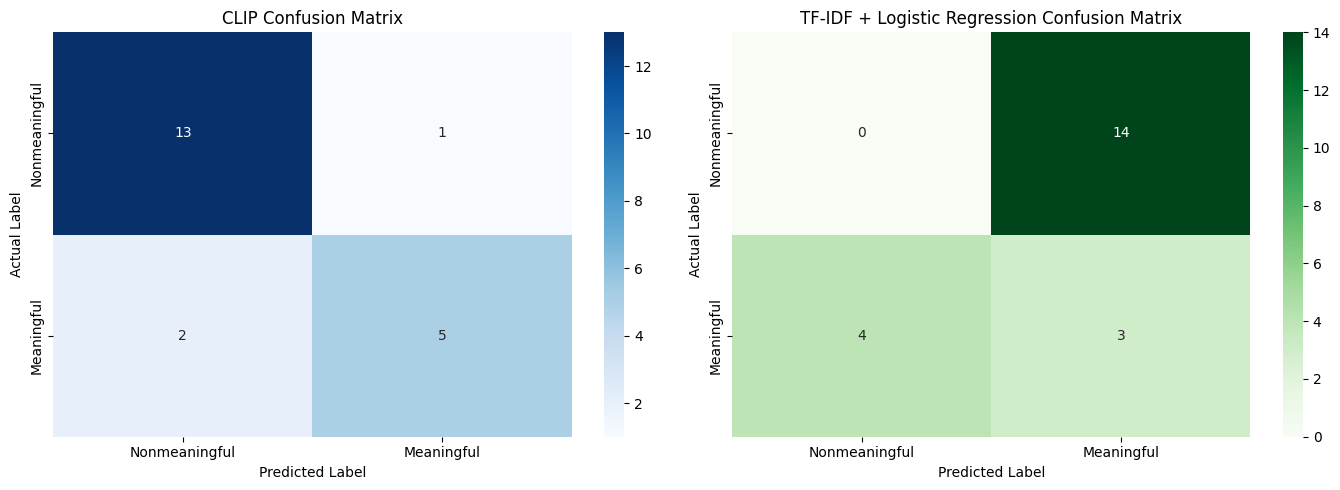

In [14]:
# ============================================================
# 10. CONFUSION MATRICES
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

clip_cm = confusion_matrix(
    y_true,
    clip_predictions
)

lr_cm = confusion_matrix(
    y_true,
    lr_predictions
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

sns.heatmap(
    clip_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Nonmeaningful",
        "Meaningful"
    ],
    yticklabels=[
        "Nonmeaningful",
        "Meaningful"
    ],
    ax=axes[0]
)

axes[0].set_title("CLIP Confusion Matrix")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")

sns.heatmap(
    lr_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=[
        "Nonmeaningful",
        "Meaningful"
    ],
    yticklabels=[
        "Nonmeaningful",
        "Meaningful"
    ],
    ax=axes[1]
)

axes[1].set_title(
    "TF-IDF + Logistic Regression Confusion Matrix"
)

axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")

plt.tight_layout()

plt.show()

In [15]:
# ============================================================
# 11. SAVE BENCHMARK EVALUATION RESULTS
# ============================================================

BENCHMARK_OUTPUT_DIR = os.path.join(
    PROJECT_DIR,
    "benchmark_model_evaluation"
)

os.makedirs(
    BENCHMARK_OUTPUT_DIR,
    exist_ok=True
)

# ------------------------------------------------------------
# SAVE METRICS
# ------------------------------------------------------------

comparison_df.to_csv(
    os.path.join(
        BENCHMARK_OUTPUT_DIR,
        "benchmark_model_comparison.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# SAVE INDIVIDUAL PREDICTIONS
# ------------------------------------------------------------

prediction_columns = [
    "document_id",
    "page_id",
    "figure_id",
    "image_path",
    "alt_text",
    "benchmark_original_label",
    "alt_text_class",
    "label",
    "clip_similarity",
    "clip_prediction",
    "lr_probability",
    "lr_prediction"
]

# Keep only columns that actually exist.
prediction_columns = [
    col for col in prediction_columns
    if col in clip_benchmark_df.columns
]

clip_benchmark_df[
    prediction_columns
].to_csv(
    os.path.join(
        BENCHMARK_OUTPUT_DIR,
        "benchmark_predictions.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# SAVE CONFUSION MATRICES
# ------------------------------------------------------------

pd.DataFrame(
    clip_cm,
    index=[
        "Actual Nonmeaningful",
        "Actual Meaningful"
    ],
    columns=[
        "Predicted Nonmeaningful",
        "Predicted Meaningful"
    ]
).to_csv(
    os.path.join(
        BENCHMARK_OUTPUT_DIR,
        "clip_confusion_matrix.csv"
    )
)

pd.DataFrame(
    lr_cm,
    index=[
        "Actual Nonmeaningful",
        "Actual Meaningful"
    ],
    columns=[
        "Predicted Nonmeaningful",
        "Predicted Meaningful"
    ]
).to_csv(
    os.path.join(
        BENCHMARK_OUTPUT_DIR,
        "logistic_regression_confusion_matrix.csv"
    )
)

# ------------------------------------------------------------
# SAVE EVALUATION CONFIGURATION
# ------------------------------------------------------------

evaluation_config = {

    "benchmark_dataset": os.path.basename(
        BENCHMARK_CSV
    ),

    "label_source": label_source,

    "positive_label": 1,
    "negative_label": 0,

    "excluded_label": "cannot_tell",

    "number_of_evaluated_records": int(
        len(clip_benchmark_df)
    ),

    "clip_similarity_threshold": float(
        CLIP_THRESHOLD
    ),

    "clip_metrics": {
        key: float(value)
        for key, value in clip_metrics.items()
    },

    "logistic_regression_metrics": {
        key: float(value)
        for key, value in lr_metrics.items()
    }

}

with open(
    os.path.join(
        BENCHMARK_OUTPUT_DIR,
        "benchmark_evaluation_config.json"
    ),
    "w"
) as f:

    json.dump(
        evaluation_config,
        f,
        indent=4
    )

print("Benchmark evaluation files saved.")

print("\nOutput directory:")
print(BENCHMARK_OUTPUT_DIR)

print("\nSaved files:")

for filename in os.listdir(
    BENCHMARK_OUTPUT_DIR
):

    print(filename)

Benchmark evaluation files saved.

Output directory:
/content/drive/MyDrive/EEE6778_Semester_Project/benchmark_model_evaluation

Saved files:
benchmark_model_comparison.csv
benchmark_predictions.csv
clip_confusion_matrix.csv
logistic_regression_confusion_matrix.csv
benchmark_evaluation_config.json
